# Crossmatch ALeRCE (Rubin/LSST) × AllWISE y TNS — campo ECDFS

**Ver este notebook en [Colab](https://colab.research.google.com/github/ale-munozarancibia/LSST_Hackdays_Medellin_Team1_Characterizing_DIAObjects/blob/main/Project/ALeRCE_LSST_crossmatch_WISE_TNS_ECDFS.ipynb)**

**Flujo**

1. **ALeRCE (TAP, `tap.alerce.online`)**: cone search de 1.75° alrededor del centro del ECDFS (RA = 52.98°, Dec = −28.12°). Se seleccionan los objetos LSST cuya clasificación principal (`ranking = 1`) del clasificador `stamp_classifier_rubin_beta_20260421` (`classifier_id = 3`) es **SN** (`class_id = 0`) o **AGN** (`class_id = 1`). El resultado es una tabla `astropy`.
2. **LSDB**: la tabla de ALeRCE se convierte a catálogo LSDB (`lsdb.from_astropy`) y se cruza por coordenadas celestes con **AllWISE** y **TNS** (catálogos HATS remotos).
3. **Resultados**: una tabla `astropy` por catálogo (solo en memoria, no se escribe nada a disco) y un resumen de matches por clase.

**Notas**
- Los radios de match (`EXTERNAL_CATALOGS`, celda de configuración) son un punto de partida: se guarda `_dist_arcsec` para poder filtrar después sin repetir el cruce.
- La primera ejecución del crossmatch puede tardar, porque LSDB descarga por HTTP las particiones de los catálogos externos que cubren la región.
- Las celdas de ALeRCE validan el esquema TAP (`alerce_tap.object` y `alerce_tap.probability`) antes de consultar. Si un nombre de columna no coincide, el error indica las columnas disponibles.

In [ ]:
!pip install -q alerce

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 44.3 MB/s eta 0:00:00


In [ ]:
!wget https://raw.githubusercontent.com/alercebroker/usecases/master/notebooks/LSST/lib_multisurvey/alerce_multisurvey_tools.py -P lib_multisurvey/

--2026-10-13 22:18:30--  https://raw.githubusercontent.com/alercebroker/usecases/master/notebooks/LSST/lib_multisurvey/alerce_multisurvey_tools.py
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.109.133, 185.199.110.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 38849 (38K) [text/plain]
Saving to: ‘lib_multisurvey/alerce_multisurvey_tools.py’

alerce_multisurvey_ 100%[===================>]  37.94K  --.-KB/s    in 0.004s  

2026-10-13 22:18:30 (10.5 MB/s) - ‘lib_multisurvey/alerce_multisurvey_tools.py’ saved [38849/38849]



In [ ]:
!pip install -q pyvo
!pip install -q lsdb

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 13.7 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.5/79.5 kB 6.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 141.5/141.5 kB 12.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 119.3/119.3 kB 9.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 120.2/120.2 kB 8.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 102.1/102.1 kB 7.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.7/16.7 MB 80.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 83.5/83.5 kB 6.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 47.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 221.7/221.7 kB 15.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 59.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.8/3.8 MB 97.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.8/10.8

In [ ]:
!pip install pandas==2.2.3 numba==0.65.1 fsspec==2025.12.0

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 89.9/89.9 kB 2.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.7/12.7 MB 91.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.8/3.8 MB 95.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 201.4/201.4 kB 14.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.3/56.3 MB 12.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.6/16.6 MB 52.0 MB/s eta 0:00:00
  Attempting uninstall: numpy
    Found existing installation: numpy 2.5.4
    Uninstalling numpy-2.5.4:
      Successfully uninstalled numpy-2.5.4
  Attempting uninstall: llvmlite
    Found existing installation: llvmlite 0.50.0
    Uninstalling llvmlite-0.50.0:
      Successfully uninstalled llvmlite-0.50.0
  Attempting uninstall: fsspec
    Found existing installation: fsspec 2026.9.0
    Uninstalling fsspec-2026.9.0:
      Successfully uninstalled fsspec-2026.9.0
  Attempting uninstall: pandas
    Found existing ins

In [ ]:
import time
import warnings

import numpy as np
import pandas as pd
import pyvo
import lsdb
from astropy.table import Table, Column, MaskedColumn, unique, vstack
from astropy.coordinates import SkyCoord
import astropy.units as u

# ----------------------------- Configuración -----------------------------
# Región: centro del ECDFS y radio del cone search
RA0, DEC0 = 52.98, -28.12          # grados
RADIUS_DEG = 1.75                  # grados

# ALeRCE (TAP)
TAP_URL = "https://tap.alerce.online/tap"
CLASSIFIER_ID = 3                  # stamp_classifier_rubin_beta_20260421
CLASSIFIER_NAME = "stamp_classifier_rubin_beta_20260421"   # solo informativo
RANKING = 1                        # clasificación principal
CLASS_MAP = {0: "SN", 1: "AGN"}    # class_id -> class_name
MAXREC = 1_000_000                 # máximo de filas que se pide al servicio TAP

# Crossmatch LSDB
HOW = "inner"                      # "inner": solo fuentes con match | "left": conserva todas las de ALeRCE
REQUIRE_RIGHT_MARGIN = False       # True: error si el catálogo externo no trae margen
CONE_BUFFER_ARCSEC = 60.0          # holgura del cone search sobre el catálogo externo

EXTERNAL_CATALOGS = {
    "AllWISE": dict(
        url="https://data.lsdb.io/hats/wise/allwise",
        radius_arcsec=2.0,
        n_neighbors=1,
        suffix="_wise",
        # Subconjunto de columnas (se usan solo las que existan). None = todas.
        columns=["designation", "source_id", "ra", "dec",
                 "w1mpro", "w1sigmpro", "w2mpro", "w2sigmpro",
                 "w3mpro", "w3sigmpro", "w4mpro", "w4sigmpro",
                 "ext_flg", "cc_flags", "ph_qual"],
    ),
    "TNS": dict(
        url="https://data.lsdb.io/hats/tns",
        radius_arcsec=2.0,
        n_neighbors=1,
        suffix="_tns",
        columns=None,   # TNS es pequeño: se conservan todas las columnas
    ),
}

# Opcional: cluster local de Dask para el crossmatch (si lo quieres, descomenta)
# from dask.distributed import Client
# client = Client(n_workers=4, threads_per_worker=1, memory_limit="4GB")

## 1. ALeRCE: cone search + clasificación (TAP)

In [ ]:
tap = pyvo.dal.TAPService(TAP_URL)


def tap_columns(tap, qualified_name):
    """Columnas de una tabla del servicio TAP (None si no se pudo leer el esquema)."""
    try:
        tables = tap.tables
        items = tables.values() if hasattr(tables, "values") else tables
        for t in items:
            if t.name == qualified_name:
                return [c.name for c in t.columns]
    except Exception as e:
        print(f"(No pude leer el esquema TAP: {type(e).__name__}: {e})")
    return None


obj_cols = tap_columns(tap, "alerce_tap.object")
prob_cols = tap_columns(tap, "alerce_tap.probability")
print("alerce_tap.object      :", obj_cols)
print("alerce_tap.probability :", prob_cols)

REQ_OBJ = ["oid", "meanra", "meandec"]
REQ_PROB = ["oid", "classifier_id", "class_id", "ranking", "probability"]
for tname, cols, req in (("alerce_tap.object", obj_cols, REQ_OBJ),
                         ("alerce_tap.probability", prob_cols, REQ_PROB)):
    if cols is not None:
        missing = [c for c in req if c not in cols]
        if missing:
            raise KeyError(f"En {tname} faltan las columnas {missing}. "
                           f"Disponibles: {cols}. Ajusta la consulta ADQL de la celda siguiente.")

alerce_tap.object      : ['oid', 'tid', 'sid', 'meanra', 'meandec', 'sigmara', 'sigmadec', 'firstmjd', 'lastmjd', 'deltamjd', 'n_det', 'n_forced', 'n_non_det', 'created_date', 'updated_date']
alerce_tap.probability : ['oid', 'sid', 'classifier_id', 'classifier_version', 'class_id', 'probability', 'ranking', 'lastmjd']


In [ ]:
# Columnas opcionales del objeto (solo si existen en el esquema)
extra = [c for c in ("n_det", "firstmjd", "lastmjd") if obj_cols is None or c in obj_cols]
select_extra = "".join(f", o.{c}" for c in extra)
class_ids = ", ".join(str(k) for k in CLASS_MAP)

adql = f"""
SELECT o.oid, o.meanra, o.meandec{select_extra},
       p.class_id, p.probability, p.ranking
FROM alerce_tap.object AS o
JOIN alerce_tap.probability AS p ON p.oid = o.oid
WHERE 1 = CONTAINS(POINT('ICRS', o.meanra, o.meandec),
                   CIRCLE('ICRS', {RA0}, {DEC0}, {RADIUS_DEG}))
  AND p.classifier_id = {CLASSIFIER_ID}
  AND p.ranking = {RANKING}
  AND p.class_id IN ({class_ids})
"""
print(adql)

t0 = time.time()
try:
    res = tap.run_sync(adql, maxrec=MAXREC)
except Exception as e:
    print(f"run_sync falló ({type(e).__name__}: {e}); reintento en modo asíncrono...")
    res = tap.run_async(adql, maxrec=MAXREC)
alerce_raw = res.to_table()
print(f"{len(alerce_raw)} filas en {time.time() - t0:.1f} s")

if len(alerce_raw) == 0:
    raise RuntimeError("La consulta no devolvió objetos. Revisa el esquema impreso arriba, "
                       "el classifier_id y que ALeRCE tenga cobertura LSST en la región.")

hardlimit = getattr(tap, "hardlimit", None)
if len(alerce_raw) >= MAXREC or (hardlimit and len(alerce_raw) >= hardlimit):
    warnings.warn("El número de filas alcanzó el límite del servicio: el resultado podría estar truncado.")


SELECT o.oid, o.meanra, o.meandec, o.n_det, o.firstmjd, o.lastmjd,
       p.class_id, p.probability, p.ranking
FROM alerce_tap.object AS o
JOIN alerce_tap.probability AS p ON p.oid = o.oid
WHERE 1 = CONTAINS(POINT('ICRS', o.meanra, o.meandec),
                   CIRCLE('ICRS', 52.98, -28.12, 1.75))
  AND p.classifier_id = 3
  AND p.ranking = 1
  AND p.class_id IN (0, 1)

9016 filas en 8.3 s


In [ ]:
alerce_tbl = alerce_raw.copy()
alerce_tbl.rename_column("meanra", "ra")
alerce_tbl.rename_column("meandec", "dec")
alerce_tbl["class_name"] = np.array([CLASS_MAP[int(i)] for i in np.asarray(alerce_tbl["class_id"])])

# Un solo registro por objeto (por si hubiera duplicados en la unión): se queda el de mayor probabilidad
if len(np.unique(alerce_tbl["oid"])) < len(alerce_tbl):
    print("Aviso: hay oid repetidos; se conserva la fila de mayor probabilidad por objeto.")
    alerce_tbl.sort("probability", reverse=True)
    alerce_tbl = unique(alerce_tbl, keys="oid", keep="first")

# Comprobaciones básicas
center = SkyCoord(RA0, DEC0, unit="deg")
coords = SkyCoord(np.asarray(alerce_tbl["ra"], dtype=float),
                  np.asarray(alerce_tbl["dec"], dtype=float), unit="deg")
sep_max = coords.separation(center).deg.max()
print(f"Separación máxima al centro: {sep_max:.3f} deg (radio pedido: {RADIUS_DEG} deg)")
if sep_max > RADIUS_DEG + 0.01:
    warnings.warn("Hay objetos fuera del cono pedido; revisa la consulta.")

print(f"\nClasificador {CLASSIFIER_NAME} (id={CLASSIFIER_ID}), ranking={RANKING}")
for cname in CLASS_MAP.values():
    sel = alerce_tbl["class_name"] == cname
    p = np.asarray(alerce_tbl["probability"])[sel]
    print(f"  {cname:>3}: {sel.sum():6d} objetos"
          + (f" | probabilidad min/mediana: {p.min():.2f} / {np.median(p):.2f}" if sel.any() else ""))

alerce_tbl[:5]

Separación máxima al centro: 1.750 deg (radio pedido: 1.75 deg)

Clasificador stamp_classifier_rubin_beta_20260421 (id=3), ranking=1
   SN:   2243 objetos | probabilidad min/mediana: 0.29 / 0.59
  AGN:   6773 objetos | probabilidad min/mediana: 0.25 / 0.65


oid,ra,dec,n_det,firstmjd,lastmjd,class_id,probability,ranking,class_name
,deg,deg,,d,d,,,,
int64,float64,float64,int32,float64,float64,int16,float32,int16,str3
313853500274507900,51.647729534478664,-27.40330124022985,1,61024.147519667975,61024.147519667975,0,0.6686041,1,SN
313967752072658995,52.69267618821874,-26.676393132586327,1,61050.10471070056,61050.10471070056,0,0.5521802,1,SN
313862199280402533,52.077396624188644,-29.24767691118903,1,61026.192734442004,61026.192734442004,1,0.5840667,1,AGN
313695088208248887,53.83772955391125,-28.58039588504365,1,60988.1344526879,60988.1344526879,1,0.44858238,1,AGN
313695088848404576,52.52094024179558,-27.98203969771295,3,60988.13963611373,61002.22960603767,1,0.9221616,1,AGN


## 2. LSDB: crossmatch con AllWISE y TNS

In [ ]:
def clean_for_lsdb(tbl, keep):
    """Copia limpia de una tabla astropy (sin columnas enmascaradas ni bytes) para lsdb.from_astropy."""
    out = Table()
    for name in keep:
        col = tbl[name]
        if isinstance(col, MaskedColumn):
            if col.dtype.kind == "f":
                data = col.filled(np.nan)
            elif col.dtype.kind in "iu":
                data = col.filled(-1)
            else:
                data = col.filled("")
        else:
            data = col
        data = np.asarray(data)
        if data.dtype.kind == "S":
            data = np.char.decode(data, "utf-8")
        out[name] = data
    return out


def pandas_to_astropy(df):
    """DataFrame (posiblemente con dtypes pyarrow/nullable) -> astropy Table."""
    cols = {}
    for name in df.columns:
        s = df[name]
        mask = s.isna().to_numpy()
        if pd.api.types.is_bool_dtype(s):
            data = s.fillna(False).to_numpy(dtype=bool)
        elif pd.api.types.is_integer_dtype(s):
            data = s.fillna(0).to_numpy(dtype="int64")
        elif pd.api.types.is_float_dtype(s):
            data = s.to_numpy(dtype="float64", na_value=np.nan)
            mask = np.zeros(len(s), dtype=bool)   # NaN ya representa el dato faltante
        else:
            data = s.astype(object).where(~s.isna(), "").to_numpy().astype(str)
        cols[name] = MaskedColumn(data, mask=mask) if mask.any() else Column(data)
    return Table(cols)


def get_radec_columns(cat):
    """Nombres de las columnas ra/dec de un catálogo LSDB."""
    try:
        info = cat.hc_structure.catalog_info
        if info.ra_column and info.dec_column:
            return info.ra_column, info.dec_column
    except Exception:
        pass
    low = {c.lower(): c for c in cat.columns}
    ra = next((low[k] for k in ("ra", "raj2000", "ra_deg") if k in low), None)
    dec = next((low[k] for k in ("dec", "dej2000", "dec_deg") if k in low), None)
    if ra is None or dec is None:
        raise KeyError(f"No pude identificar ra/dec en: {list(cat.columns)[:30]}")
    return ra, dec


def match_summary(left_tbl, xm_tbl, label, class_col="class_name", suffix="_alerce"):
    """Por clase: fuentes de ALeRCE, fuentes con match, fracción y distancia mediana."""
    rows = []
    cc, oc = class_col + suffix, "oid" + suffix
    dist = np.asarray(xm_tbl["_dist_arcsec"], dtype=float)
    for cname in sorted(set(left_tbl[class_col])):
        n_tot = int(np.sum(left_tbl[class_col] == cname))
        sel = (np.asarray(xm_tbl[cc]) == cname) & np.isfinite(dist)
        n_match = len(np.unique(np.asarray(xm_tbl[oc])[sel]))
        rows.append((label, cname, n_tot, n_match,
                     round(n_match / n_tot, 3) if n_tot else np.nan,
                     round(float(np.median(dist[sel])), 3) if sel.any() else np.nan))
    return Table(rows=rows, names=("catalogo", "clase", "N_ALeRCE", "N_con_match",
                                   "fraccion", "dist_mediana_arcsec"))

In [ ]:
# Tabla de ALeRCE -> catálogo LSDB (catálogo izquierdo del crossmatch)
keep = [c for c in ("oid", "ra", "dec", "class_id", "class_name", "probability",
                    "ranking", "n_det", "firstmjd", "lastmjd") if c in alerce_tbl.colnames]
alerce_lsdb = lsdb.from_astropy(clean_for_lsdb(alerce_tbl, keep),
                                ra_column="ra", dec_column="dec",
                                catalog_name="alerce_lsst")
print(alerce_lsdb)

lsdb Catalog alerce_lsst:
                                oid               ra              dec        class_id       class_name     probability         ranking           n_det         firstmjd          lastmjd
npartitions=1                                                                                                                                                                           
Order: 1, Pixel: 35  int64[pyarrow]  double[pyarrow]  double[pyarrow]  int16[pyarrow]  string[pyarrow]  float[pyarrow]  int16[pyarrow]  int32[pyarrow]  double[pyarrow]  double[pyarrow]
10 out of 10 available columns in the catalog have been loaded lazily, meaning no data has been read, only the catalog schema
This catalog has an estimated size of 529.4 KB


In [ ]:
cone_radius_arcsec = RADIUS_DEG * 3600.0 + CONE_BUFFER_ARCSEC
xmatch = {}   # nombre del catálogo -> astropy Table

for name, cfg in EXTERNAL_CATALOGS.items():
    print(f"\n=== ALeRCE x {name} ===")

    # 1) Abrir (perezoso) e inspeccionar
    probe = lsdb.open_catalog(cfg["url"])
    ra_c, dec_c = get_radec_columns(probe)
    all_cols = list(probe.columns)
    print(f"{len(all_cols)} columnas | ra/dec = ({ra_c}, {dec_c})")
    if getattr(probe, "margin", None) is None:
        warnings.warn(f"{name}: el catálogo no trae margen; podrían perderse matches en los bordes de partición.")

    # 2) Selección de columnas
    cols = None
    if cfg["columns"]:
        wanted = [c for c in cfg["columns"] if c in all_cols and c not in (ra_c, dec_c)]
        if wanted:
            cols = [ra_c, dec_c] + wanted
        else:
            warnings.warn(f"{name}: ninguna columna candidata existe; se usan todas.")
    right = lsdb.open_catalog(cfg["url"], columns=cols) if cols else probe

    # 3) Recorte espacial al cono de ECDFS (antes de cualquier descarga)
    right = right.cone_search(RA0, DEC0, cone_radius_arcsec)

    # 4) Crossmatch (ALeRCE a la izquierda)
    xm = alerce_lsdb.crossmatch(
        right,
        n_neighbors=cfg["n_neighbors"],
        radius_arcsec=cfg["radius_arcsec"],
        how=HOW,
        suffixes=("_alerce", cfg["suffix"]),
        suffix_method="all_columns",
        require_right_margin=REQUIRE_RIGHT_MARGIN,
        output_catalog_name=f"alerce_x_{name.lower()}",
    )

    # 5) Ejecutar y pasar a astropy
    t0 = time.time()
    df = xm.compute()
    xmatch[name] = pandas_to_astropy(df.reset_index(drop=True))
    print(f"{len(xmatch[name])} filas en {time.time() - t0:.1f} s")


=== ALeRCE x AllWISE ===
299 columnas | ra/dec = (ra, dec)


Computing Catalog:   0%|          | 0/11 [00:00<?, ?it/s]

4736 filas en 6.1 s

=== ALeRCE x TNS ===
23 columnas | ra/dec = (ra, declination)


Computing Catalog:   0%|          | 0/6 [00:00<?, ?it/s]

39 filas en 0.8 s


## 3. Resultados

In [ ]:
summary = vstack([match_summary(alerce_tbl, xmatch[n], n) for n in xmatch])
print(f"Radios de match: " + ", ".join(f"{n} = {c['radius_arcsec']}\"" for n, c in EXTERNAL_CATALOGS.items()))
summary

Radios de match: AllWISE = 2.0", TNS = 2.0"


catalogo,clase,N_ALeRCE,N_con_match,fraccion,dist_mediana_arcsec
str7,str3,int64,int64,float64,float64
AllWISE,AGN,6773,4010,0.592,0.57
AllWISE,SN,2243,726,0.324,1.299
TNS,AGN,6773,14,0.002,0.117
TNS,SN,2243,25,0.011,0.029


In [ ]:
# Tablas astropy resultantes: xmatch["AllWISE"], xmatch["TNS"]
# Columnas: <col>_alerce, <col>_wise / <col>_tns y _dist_arcsec (distancia del match, en arcsec)
xmatch["AllWISE"]

oid_alerce,ra_alerce,dec_alerce,class_id_alerce,class_name_alerce,probability_alerce,ranking_alerce,n_det_alerce,firstmjd_alerce,lastmjd_alerce,ra_wise,dec_wise,designation_wise,source_id_wise,w1mpro_wise,w1sigmpro_wise,w2mpro_wise,w2sigmpro_wise,w3mpro_wise,w3sigmpro_wise,w4mpro_wise,w4sigmpro_wise,ext_flg_wise,cc_flags_wise,ph_qual_wise,_dist_arcsec
int64,float64,float64,int64,str3,float64,int64,int64,float64,float64,float64,float64,str19,str20,float64,float64,float64,float64,float64,float64,float64,float64,int64,str4,str4,float64
313967752072658995,52.69267618821874,-26.676393132586327,0,SN,0.5521801710128784,1,1,61050.10471070056,61050.10471070056,52.692529,-26.6766711,J033046.20-264036.0,0523m273_ac51-056910,17.948,0.167,17.236,0.331,12.666,nan,9.306,nan,0,0000,BBUU,1.107043077817407
313695088208248887,53.83772955391125,-28.58039588504365,1,AGN,0.44858238101005554,1,1,60988.1344526879,60988.1344526879,53.83748,-28.5807252,J033520.99-283450.6,0531m288_ac51-050343,13.199,0.023,13.069,0.026,12.085,0.193,8.966,nan,5,0000,AABU,1.4240386799336295
313695088848404576,52.52094024179558,-27.98203969771295,1,AGN,0.9221615791320801,1,3,60988.13963611373,61002.22960603767,52.5210586,-27.9821369,J033005.05-275855.6,0523m273_ac51-006539,16.536,0.054,16.116,0.129,12.659,nan,9.239,nan,0,0000,ABUU,0.5138427143162808
313967751878148431,52.912647915723355,-28.706085595067957,1,AGN,0.47544214129447937,1,1,61050.10431275153,61050.10431275153,52.9129361,-28.7061753,J033139.10-284222.2,0531m288_ac51-035878,17.412,0.119,17.367,0.395,12.746,nan,9.507,nan,0,0000,BCUU,0.9655592038190037
314002968446240294,52.967442491743036,-29.807615817462366,1,AGN,0.3932487964630127,1,1,61058.08415442709,61058.08415442709,52.9674225,-29.8076047,J033152.18-294827.3,0521m303_ac51-053775,17.089,0.084,17.037,0.279,12.936,nan,9.294,nan,0,0000,ABUU,0.07417312986507653
313967752162312290,53.39007214843028,-28.23427972876589,1,AGN,0.7516171336174011,1,1,61050.105107476775,61050.105107476775,53.3900054,-28.2344985,J033333.60-281404.1,0531m288_ac51-056224,17.035,0.08,15.975,0.11,12.598,nan,8.969,nan,0,0000,ABUU,0.8155337251545095
313967752473739355,52.822099124537964,-26.914822756170107,1,AGN,0.4487108886241913,1,1,61050.10589764087,61050.10589764087,52.8218838,-26.9149525,J033117.25-265453.8,0523m273_ac51-047661,16.149,0.044,16.067,0.121,12.858,0.377,9.275,0.41,0,0000,ABCC,0.8342193605353321
313998536298463234,51.4268098543738,-29.18784164792652,1,AGN,0.7588849663734436,1,1,61057.15381086441,61057.15381086441,51.4268351,-29.1879495,J032542.44-291116.6,0514m288_ac51-018595,16.025,0.044,15.782,0.096,12.059,0.209,9.038,0.383,0,0000,AABC,0.3962917259322397
314002968577835128,53.25191474455074,-29.51987815879259,1,AGN,0.47399038076400757,1,1,61058.08455433715,61058.08455433715,53.251833,-29.519812,J033300.43-293111.3,0531m288_ac51-007043,18.067,0.19,17.255,nan,12.755,nan,9.493,nan,0,0000,BUUU,0.34971686201477664


In [ ]:
xmatch["TNS"].to_pandas()

,oid_alerce,ra_alerce,dec_alerce,class_id_alerce,class_name_alerce,probability_alerce,ranking_alerce,n_det_alerce,firstmjd_alerce,lastmjd_alerce,...,discmagfilter_tns,filter_tns,reporters_tns,time_received_tns,internal_names_tns,Discovery_ADS_bibcode_tns,Class_ADS_bibcodes_tns,creationdate_tns,lastmodified_tns,_dist_arcsec
0,313879818637672472,54.287013,-28.161451,1,AGN,0.378095,1,1,61030.286695,61030.286695,...,26.0,w,"K. C. Chambers, T. de Boer, J. Bulger, J. Fair...",2021-09-02 12:09:37,PS21jsh,2021TNSTR3010....1C,NaN,2021-09-02 12:09:38,2021-09-02 12:09:38,0.989418
1,313699514821640259,51.620550,-28.114119,0,SN,0.965387,1,129,60989.260516,61108.032716,...,58.0,i,"D. O. Jones (UC Santa Cruz), K. D. French (Car...",2025-12-26 20:21:40,"PS25isv, ATLAS26aym",2025TNSTR5176....1J,NaN,2025-12-26 20:21:42,2025-12-26 20:21:42,0.153674
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
37,170019695992242795,52.823855,-29.691604,0,SN,0.991934,1,8,61088.093945,61107.030002,...,162.0,r,"I. Pérez-Fournon (IAC and ULL), D. Cano-Morale...",2026-04-16 23:14:23,LSST-AP-DO-170019695992242795,2026TNSTR1651....1P,NaN,2026-04-16 23:14:24,2026-04-16 23:14:24,0.031253
38,313950161050533922,52.789899,-28.540200,1,AGN,0.523554,1,81,61046.157250,61103.036815,...,162.0,r,"A.E. Hernández-Díaz (ULL), I. Pérez-Fournon (I...",2026-03-06 01:24:12,LSST-AP-DO-313950161050533922,2026TNSTR.934....1H,NaN,2026-03-06 01:24:13,2026-03-06 01:24:13,0.011622


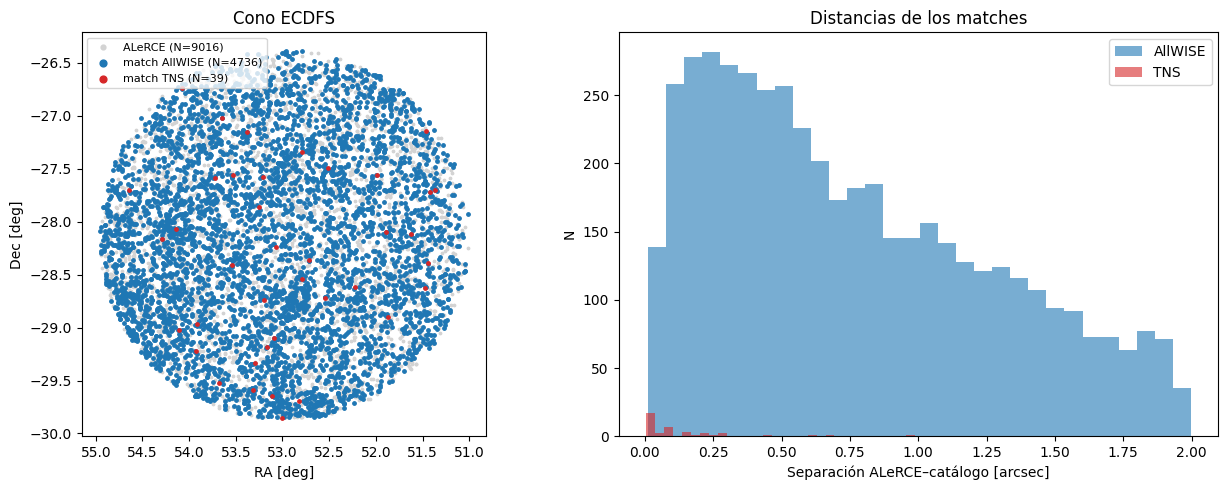

In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Mapa del cono: objetos de ALeRCE y los que tienen match
ax = axes[0]
ra_all = np.asarray(alerce_tbl["ra"], dtype=float)
dec_all = np.asarray(alerce_tbl["dec"], dtype=float)
ax.scatter(ra_all, dec_all, s=3, c="lightgray", label=f"ALeRCE (N={len(alerce_tbl)})")
colors = {"AllWISE": "tab:blue", "TNS": "tab:red"}
for name, tbl in xmatch.items():
    ok = np.isfinite(np.asarray(tbl["_dist_arcsec"], dtype=float))
    ax.scatter(np.asarray(tbl["ra_alerce"], dtype=float)[ok], np.asarray(tbl["dec_alerce"], dtype=float)[ok],
               s=6, c=colors.get(name, None), label=f"match {name} (N={ok.sum()})")
ax.set_aspect(1 / np.cos(np.deg2rad(DEC0)))
ax.invert_xaxis()
ax.set_xlabel("RA [deg]"); ax.set_ylabel("Dec [deg]")
ax.set_title("Cono ECDFS"); ax.legend(markerscale=2, fontsize=8)

# Distribución de separaciones
ax = axes[1]
for name, tbl in xmatch.items():
    d = np.asarray(tbl["_dist_arcsec"], dtype=float)
    d = d[np.isfinite(d)]
    if len(d):
        ax.hist(d, bins=30, alpha=0.6, label=name, color=colors.get(name, None))
ax.set_xlabel("Separación ALeRCE–catálogo [arcsec]"); ax.set_ylabel("N")
ax.set_title("Distancias de los matches"); ax.legend()

plt.tight_layout()
plt.show()